# Lab 1 — Intro to Behavioral TV Data
Name: Volkov Oleksii | Group: KM-42

## Setup

In [36]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")
# Colab and Kaggle
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


### WATCH OUT
**Rules for this lab** (so everyone gets the same numbers):
* a household or person has watched a telecast if they watched at least 1 minute of it;
* **persons** are R and L only; S guests are left out of every person number, because a guest id does
not identify a person;
* a telecast’s **rating** = sum of the weights of those who watched it ÷ sum of the weights of
everyone in-tab that broadcast day (in the same group: households, P2+, A18–34, ...) ×100;
* for **reach** over several days, give each person one weight for the month: their average weight
over the broadcast days they were in-tab. Reach = sum of these weights over people who
watched at least once ÷ sum over everyone in the group ×100. (The industry uses one fixed
weight per person for the whole period; the average is our stand-in for it.)

In [37]:
import numpy as np
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"]).astype("datetime64[ns]")


def abs_time(s):
    """Absolute time: for session lengths and for cutting sessions at hour boundaries."""
    s = pd.to_datetime(s)
    return s.dt.tz_convert("UTC") if s.dt.tz is not None else s


def et_clock(s):
    """US Eastern wall-clock time: for hour of day and broadcast day."""
    s = pd.to_datetime(s)
    if s.dt.tz is not None:
        s = s.dt.tz_convert("America/New_York").dt.tz_localize(None)
    return s.astype("datetime64[ns]")


def broadcast_day(s):
    """Broadcast day runs 06:00–05:59, so Friday 01:00 belongs to Thursday."""
    return (et_clock(s) - pd.Timedelta(hours=6)).dt.normalize()


PERSONS = ["R", "L"]
dw = daily_weights
BDAYS = pd.Series(np.sort(dw.broadcast_date.unique()))
print("Broadcast days in daily_weights:", BDAYS.min().date(), "...", BDAYS.max().date(), f"({len(BDAYS)} days)")
print("viewings timestamps carry a time zone:", viewings.start_ts.dt.tz is not None)

Broadcast days in daily_weights: 2024-10-01 ... 2024-10-31 (31 days)
viewings timestamps carry a time zone: False


## Task 1.1 — Panel and universe

In [38]:
hh = dw[dw.resp_type == "H"]
pp = dw[dw.resp_type.isin(PERSONS)]
hh_day = hh.groupby("broadcast_date").agg(n=("respondent_id", "nunique"), w=("weight", "sum"))
pp_day = pp.groupby("broadcast_date").agg(n=("respondent_id", "nunique"), w=("weight", "sum"))

In [39]:
print("Telecasts:", len(programs))
print("Programs:", programs.program_name.nunique())
print("Networks:", programs.network_code.nunique())
print("Households in panel:", hh.respondent_id.nunique())
print("Persons in panel:", pp.respondent_id.nunique())
print("Households in-tab, average day:", round(hh_day.n.mean()))
print("Persons in-tab, average day:", round(pp_day.n.mean()))
print("US TV households represented, average day (M):", round(hh_day.w.mean() / 1e6, 2))
print("US persons represented, average day (M):", round(pp_day.w.mean() / 1e6, 2))

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878
Persons in-tab, average day: 9269
US TV households represented, average day (M): 125.8
US persons represented, average day (M): 317.28


In [40]:
# Why does viewer_attributes list a few more?
TYPE_CODE = {104: "H", 101: "R", 102: "L"}
va_type = (viewer_attributes[viewer_attributes.attr_id.isin(TYPE_CODE)]
           .assign(resp_type=lambda d: d.attr_id.map(TYPE_CODE))
           .drop_duplicates("respondent_id"))
never_in_tab = va_type[~va_type.respondent_id.isin(dw.respondent_id)]

print("In viewer_attributes:", va_type.resp_type.value_counts().to_dict())
print("In daily_weights:    ", dw.drop_duplicates("respondent_id").resp_type.value_counts().to_dict())
print("Never in-tab in October:", never_in_tab.resp_type.value_counts().to_dict())
print("...their viewing sessions:", viewings.respondent_id.isin(never_in_tab.respondent_id).sum())

In viewer_attributes: {'R': 10095, 'H': 4256, 'L': 121}
In daily_weights:     {'R': 10089, 'H': 4254, 'L': 121}
Never in-tab in October: {'R': 6, 'H': 2}
...their viewing sessions: 0


**Answer:** `programs` holds **5,841 telecasts** of **246 distinct programs** on **10 networks**, and **4,254 households** and **10,210 persons** were in-tab at least once in October; `viewer_attributes` lists **8 more records** (2 households, 6 persons) because it describes everyone enrolled in the panel, including people who were never in-tab in October and so have no weight and no viewing. On an average day **3,878 households** and **9,269 persons** are in-tab (about 91% of the panel, as homes join and leave and meters fail), and their weights add up to the full universe of **125.8 M** US TV households and **317.28 M** persons 2+.

## Task 1.2 — Average audience by hour of day

In [41]:
# 1) person sessions only (R + L)
s = viewings.loc[viewings.resp_type.isin(PERSONS)]
s = pd.DataFrame({"start": abs_time(s.start_ts), "end": abs_time(s.end_ts), "weight": s.weight})
print("Person sessions:", len(s), "| with end <= start (skipped):", int((s.end <= s.start).sum()))
s = s[s.end > s.start]
total_wmin = ((s.end - s.start).dt.total_seconds() / 60 * s.weight).sum()

# 2) cut every session at clock-hour boundaries: 20:50–21:20 -> 10 min in hour 20 + 20 min in hour 21
pieces = []
while len(s):
    boundary = s.start.dt.floor("h") + pd.Timedelta(hours=1)
    cut = s.end.where(s.end < boundary, boundary)
    pieces.append(pd.DataFrame({"start": s.start,
                                "minutes": (cut - s.start).dt.total_seconds() / 60,
                                "weight": s.weight}))
    s = s.assign(start=cut)
    s = s[s.start < s.end]
p = pd.concat(pieces, ignore_index=True)

# 3) weighted minutes, clock hour, broadcast day, weekday / weekend
p["wmin"] = p.minutes * p.weight
p["hour"] = et_clock(p.start).dt.hour
p["bday"] = broadcast_day(p.start)
outside = ~p.bday.isin(BDAYS)
print(f"Viewing outside the October broadcast days (dropped): {p.wmin[outside].sum() / p.wmin.sum():.2%}")
p = p[~outside]
p["weekend"] = p.bday.dt.dayofweek >= 5
n_days = {False: int((BDAYS.dt.dayofweek < 5).sum()), True: int((BDAYS.dt.dayofweek >= 5).sum())}
print("Broadcast days — weekdays:", n_days[False], "| weekends:", n_days[True])

# 4) average audience = weighted minutes in that hour / 60 / number of such days
HOURS = list(range(6, 24)) + list(range(0, 6))
wm = p.groupby(["hour", "weekend"]).wmin.sum().unstack().reindex(HOURS).fillna(0)
aa = pd.DataFrame({"Weekday": wm[False] / 60 / n_days[False] / 1e6,
                   "Weekend": wm[True] / 60 / n_days[True] / 1e6})

Person sessions: 523259 | with end <= start (skipped): 0
Viewing outside the October broadcast days (dropped): 0.00%
Broadcast days — weekdays: 23 | weekends: 8


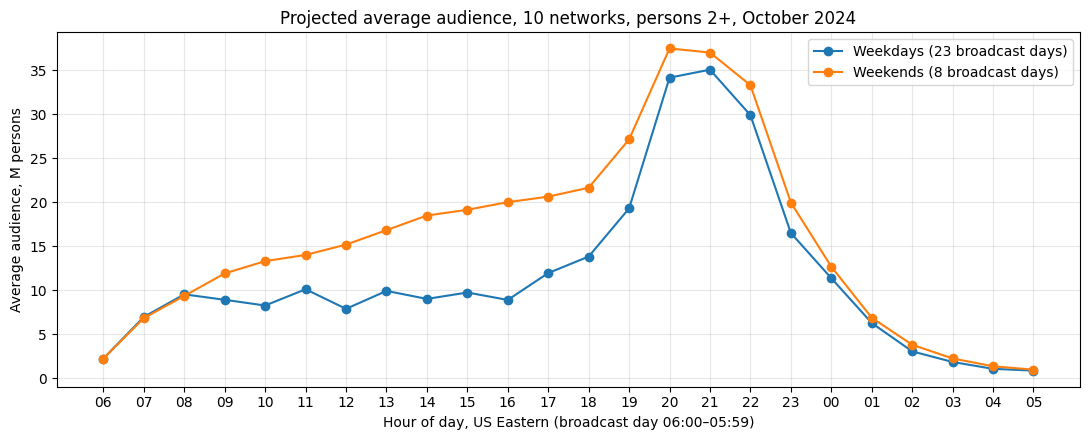

In [42]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(HOURS))
ax.plot(x, aa.Weekday, marker="o", label=f"Weekdays ({n_days[False]} broadcast days)")
ax.plot(x, aa.Weekend, marker="o", label=f"Weekends ({n_days[True]} broadcast days)")
ax.set_xticks(x, [f"{h:02d}" for h in HOURS])
ax.set_xlabel("Hour of day, US Eastern (broadcast day 06:00–05:59)")
ax.set_ylabel("Average audience, M persons")
ax.set_title(f"Projected average audience, 10 networks, persons 2+, {BDAYS.min():%B %Y}")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [43]:
print(aa.round(2).to_string())
print("Peak hour, weekdays:", f"{aa.Weekday.idxmax():02d}:00–{aa.Weekday.idxmax():02d}:59",
      f"({aa.Weekday.max():.2f} M)")
print("Peak hour, weekends:", f"{aa.Weekend.idxmax():02d}:00–{aa.Weekend.idxmax():02d}:59",
      f"({aa.Weekend.max():.2f} M)")

# numbers for "how does the weekend differ"
BLOCKS = {"06–09": range(6, 9), "09–16": range(9, 16), "16–20": range(16, 20),
          "20–23": range(20, 23), "23–02": [23, 0, 1], "02–06": range(2, 6), "whole day": HOURS}
cmp = pd.DataFrame({name: aa.loc[list(h)].mean() for name, h in BLOCKS.items()}).T
cmp["weekend vs weekday"] = (cmp.Weekend / cmp.Weekday - 1).map("{:+.0%}".format)
print(cmp.round(2).to_string())

      Weekday  Weekend
hour                  
6        2.26     2.25
7        6.99     6.86
8        9.55     9.37
9        8.93    11.93
10       8.28    13.33
11      10.13    14.03
12       7.91    15.20
13       9.94    16.85
14       9.03    18.51
15       9.76    19.16
16       8.92    20.03
17      11.97    20.65
18      13.84    21.66
19      19.32    27.16
20      34.17    37.49
21      35.08    37.02
22      29.91    33.31
23      16.52    19.99
0       11.39    12.69
1        6.30     6.89
2        3.08     3.83
3        1.87     2.27
4        1.09     1.38
5        0.89     1.00
Peak hour, weekdays: 21:00–21:59 (35.08 M)
Peak hour, weekends: 20:00–20:59 (37.49 M)
           Weekday  Weekend weekend vs weekday
06–09         6.27     6.16                -2%
09–16         9.14    15.57               +70%
16–20        13.51    22.38               +66%
20–23        33.05    35.94                +9%
23–02        11.40    13.19               +16%
02–06         1.73     2.12       

**Answer:** Viewing peaks in prime time: at **21:00–21:59** on weekdays (**35.1 M** persons in an average minute) and an hour earlier, **20:00–20:59**, on weekends (**37.5 M**). Mornings look the same, but weekend daytime is far higher (09–16: 15.6 M vs 9.1 M, **+70%**) and keeps rising through the afternoon, while prime time differs by only 9%, so over the whole day the weekend has **35%** more viewers per minute.

## Task 1.3 — Session length

In [44]:
v = viewings.loc[viewings.resp_type.isin(PERSONS), ["start_ts", "end_ts", "weight"]].copy()
v["len_min"] = (abs_time(v.end_ts) - abs_time(v.start_ts)).dt.total_seconds() / 60
keep = broadcast_day(v.start_ts).isin(BDAYS) & (v.len_min > 0)
print("Person sessions:", len(v), "| dropped (outside October or length <= 0):", int((~keep).sum()))
v = v[keep]


def weighted_median(x, w):
    order = np.argsort(np.asarray(x))
    x, cw = np.asarray(x)[order], np.cumsum(np.asarray(w)[order])
    return x[np.searchsorted(cw, cw[-1] / 2)]


w_mean = np.average(v.len_min, weights=v.weight)
w_median = weighted_median(v.len_min, v.weight)

Person sessions: 523259 | dropped (outside October or length <= 0): 0


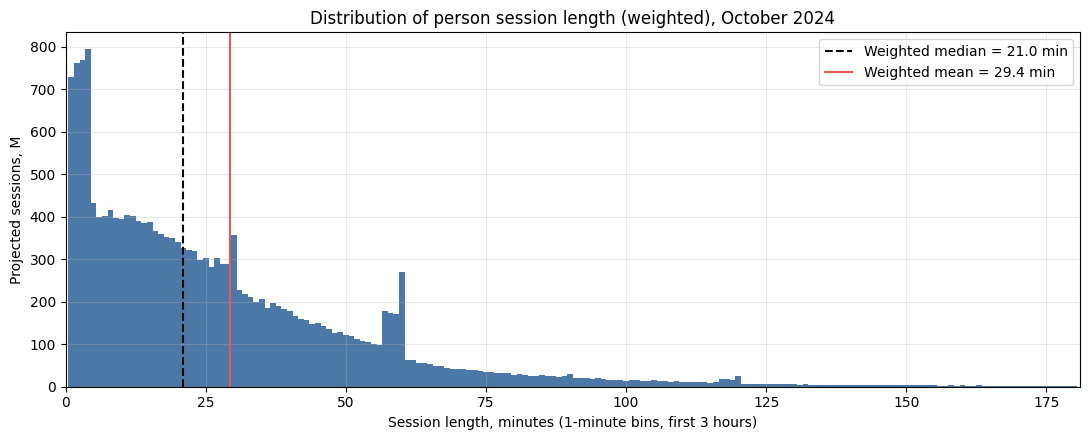

In [45]:
fig, ax = plt.subplots(figsize=(11, 4.5))
bins = np.arange(0.5, 181, 1)
ax.hist(v.len_min, bins=bins, weights=v.weight / 1e6, color="#4C78A8")
ax.axvline(w_median, color="black", ls="--", label=f"Weighted median = {w_median:.1f} min")
ax.axvline(w_mean, color="#E45756", ls="-", label=f"Weighted mean = {w_mean:.1f} min")
ax.set_xlim(0, 181)
ax.set_xlabel("Session length, minutes (1-minute bins, first 3 hours)")
ax.set_ylabel("Projected sessions, M")
ax.set_title(f"Distribution of person session length (weighted), {BDAYS.min():%B %Y}")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [46]:
print("Session length, weighted mean (min):", round(w_mean, 1))
print("Session length, weighted median (min):", round(w_median, 1))

# numbers for the answer
w, wl = v.weight, v.len_min * v.weight
long_ = v.len_min > 120
print(f"Sessions of 5 min or less: {w[v.len_min <= 5].sum() / w.sum():.0%}")
print(f"Sessions over 2 h: {w[long_].sum() / w.sum():.1%} of sessions, "
      f"but {wl[long_].sum() / wl.sum():.0%} of all viewing minutes")
print(f"Sessions over 3 h (not on the plot): {w[v.len_min > 180].sum() / w.sum():.1%}")

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0
Sessions of 5 min or less: 18%
Sessions over 2 h: 1.7% of sessions, but 9% of all viewing minutes
Sessions over 3 h (not on the plot): 0.5%


**Answer:** The weighted mean session lasts **29.4 min** and the weighted median **21.0 min**; they differ because the distribution is right-skewed: **18%** of sessions last 5 minutes or less, while a long tail of multi-hour sessions (**1.7%** of sessions are over 2 hours but hold **9%** of all minutes) pulls the mean up. In a client deck I would show the **median** ("half of all sessions are shorter than 21 minutes"), since it describes a typical session and is not inflated by rare marathon sessions.

## Task 2 — Program reach curve

In [47]:
# the telecasts: CBS Evening News on weekdays, in air order
prog = programs.assign(start_ts=et_clock(programs.start_ts), end_ts=et_clock(programs.end_ts),
                       broadcast_date=pd.to_datetime(programs.broadcast_date).astype("datetime64[ns]"))
is_news = (prog.network_code == "CBS") & prog.program_name.str.contains("Evening News", case=False, na=False)
weekday = prog.broadcast_date.dt.dayofweek < 5
news = prog[is_news & weekday].sort_values("start_ts").reset_index(drop=True)
news["k"] = np.arange(1, len(news) + 1)
print("Matched titles:", prog.loc[is_news, "program_name"].value_counts().to_dict())
print("Telecasts:", len(news), "| weekend airings left out:", int((is_news & ~weekday).sum()),
      "| start times:", news.start_ts.dt.strftime("%H:%M").value_counts().to_dict(),
      "| repeats:", int(news.is_repeat.sum()))


def who_watched(telecasts, network):
    """Who watched each telecast: at least 1 minute of it, summed over all their sessions (lab rule).
    Guests are left out; each viewer gets that broadcast day's weight, so only people in-tab that day count.
    `telecasts` needs the columns k (air order), telecast_id, broadcast_date, start_ts, end_ts."""
    sess = viewings[(viewings.network_code == network) & viewings.resp_type.isin(["H", "R", "L"])]
    sess = sess.assign(start_ts=et_clock(sess.start_ts), end_ts=et_clock(sess.end_ts))
    parts = []
    for t in telecasts.itertuples():
        s = sess[(sess.start_ts < t.end_ts) & (sess.end_ts > t.start_ts)]
        overlap = (s.end_ts.where(s.end_ts < t.end_ts, t.end_ts)
                   - s.start_ts.where(s.start_ts > t.start_ts, t.start_ts))
        parts.append(pd.DataFrame({"k": t.k, "telecast_id": t.telecast_id, "broadcast_date": t.broadcast_date,
                                   "respondent_id": s.respondent_id, "resp_type": s.resp_type,
                                   "minutes": overlap.dt.total_seconds() / 60}))
    out = (pd.concat(parts)
           .groupby(["k", "telecast_id", "broadcast_date", "respondent_id", "resp_type"], as_index=False)
           .minutes.sum())
    out = out[out.minutes >= 1]
    n_watched = len(out)
    out = out.merge(dw[["respondent_id", "broadcast_date", "weight"]], on=["respondent_id", "broadcast_date"])
    out["group"] = np.where(out.resp_type == "H", "HH", "P2+")
    print("Viewers without an in-tab weight that day (dropped):", n_watched - len(out))
    return out


viewers = who_watched(news, "CBS")

Matched titles: {'CBS Evening News': 23}
Telecasts: 23 | weekend airings left out: 0 | start times: {'18:30': 23} | repeats: 0
Viewers without an in-tab weight that day (dropped): 0


In [48]:
# 2.1 household rating, P2+ rating and projected audience of each telecast
num = (viewers.pivot_table(index="telecast_id", columns="group", values="weight", aggfunc="sum")
       .reindex(news.telecast_id).fillna(0))
den = (dw.assign(group=np.where(dw.resp_type == "H", "HH", "P2+"))
       .pivot_table(index="broadcast_date", columns="group", values="weight", aggfunc="sum")
       .reindex(news.broadcast_date))
ratings = pd.DataFrame({
    "aired": news.start_ts.dt.strftime("%a %b %d %H:%M").to_numpy(),
    "HH rating": num["HH"].to_numpy() / den["HH"].to_numpy() * 100,
    "P2+ rating": num["P2+"].to_numpy() / den["P2+"].to_numpy() * 100,
    "P2+ audience (M)": num["P2+"].to_numpy() / 1e6,
}, index=pd.Index(news.k, name="telecast"))
print(ratings.round(2).to_string())
print(ratings.drop(columns="aired").agg(["mean", "min", "max"]).round(2).to_string())

                     aired  HH rating  P2+ rating  P2+ audience (M)
telecast                                                           
1         Tue Oct 01 18:30       3.47        1.67              5.28
2         Wed Oct 02 18:30       3.07        1.48              4.68
3         Thu Oct 03 18:30       2.99        1.47              4.68
4         Fri Oct 04 18:30       3.00        1.51              4.81
5         Mon Oct 07 18:30       3.06        1.52              4.83
6         Tue Oct 08 18:30       3.17        1.57              4.97
7         Wed Oct 09 18:30       2.98        1.48              4.70
8         Thu Oct 10 18:30       3.38        1.62              5.13
9         Fri Oct 11 18:30       3.09        1.48              4.69
10        Mon Oct 14 18:30       2.93        1.45              4.59
11        Tue Oct 15 18:30       3.07        1.52              4.82
12        Wed Oct 16 18:30       3.01        1.46              4.62
13        Thu Oct 17 18:30       3.36        1.6

Persons without an age: 0


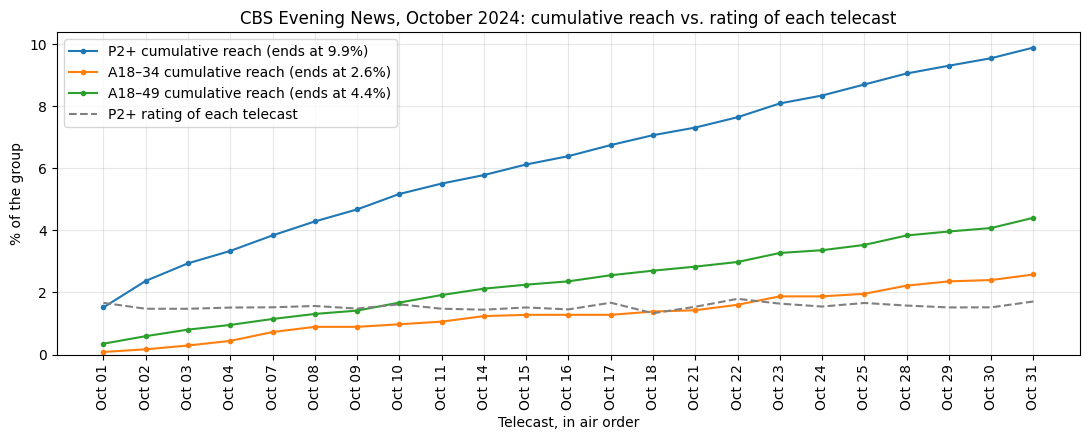

           P2+  A18–34  A18–49   A50+
telecast                             
1         1.52    0.08    0.35   3.49
2         2.37    0.17    0.59   5.41
3         2.94    0.29    0.80   6.56
4         3.34    0.44    0.96   7.36
5         3.84    0.73    1.15   8.41
6         4.29    0.89    1.31   9.36
7         4.67    0.89    1.42  10.26
8         5.17    0.98    1.68  11.14
9         5.51    1.06    1.92  11.67
10        5.78    1.24    2.12  12.05
11        6.12    1.28    2.25  12.71
12        6.39    1.28    2.36  13.28
13        6.75    1.28    2.56  13.93
14        7.06    1.39    2.70  14.42
15        7.31    1.43    2.83  14.89
16        7.64    1.60    2.98  15.52
17        8.09    1.88    3.27  16.17
18        8.34    1.88    3.36  16.65
19        8.70    1.96    3.53  17.29
20        9.05    2.22    3.84  17.80
21        9.30    2.36    3.96  18.27
22        9.54    2.40    4.08  18.69
23        9.89    2.58    4.41  19.10


In [49]:
# 2.2 cumulative reach in air order: one weight per person for the month (average of in-tab daily weights)
month_w = dw[dw.resp_type.isin(PERSONS)].groupby("respondent_id").weight.mean()
age = (viewer_attributes[viewer_attributes.attr_id == 300]
       .drop_duplicates("respondent_id").set_index("respondent_id").value.reindex(month_w.index))
print("Persons without an age:", int(age.isna().sum()))
GROUPS = {"P2+": pd.Series(True, index=month_w.index),
          "A18–34": age.between(18, 34),
          "A18–49": age.between(18, 49),
          "A50+": age >= 50}

first_k = viewers[viewers.group == "P2+"].groupby("respondent_id").k.min()
reach = pd.DataFrame(index=pd.Index(news.k, name="telecast"))
for g, in_g in GROUPS.items():
    w = month_w[in_g]
    new_people = w.reindex(first_k.index).dropna().groupby(first_k).sum()
    reach[g] = new_people.reindex(reach.index, fill_value=0).cumsum() / w.sum() * 100

fig, ax = plt.subplots(figsize=(11, 4.5))
x = reach.index
for g in ["P2+", "A18–34", "A18–49"]:
    ax.plot(x, reach[g], marker="o", ms=3, label=f"{g} cumulative reach (ends at {reach[g].iloc[-1]:.1f}%)")
ax.plot(x, ratings["P2+ rating"], color="grey", ls="--", label="P2+ rating of each telecast")
ax.set_xticks(x, news.start_ts.dt.strftime("%b %d"), rotation=90)
ax.set_xlabel("Telecast, in air order")
ax.set_ylabel("% of the group")
ax.set_title(f"CBS Evening News, {BDAYS.min():%B %Y}: cumulative reach vs. rating of each telecast")
ax.set_ylim(0, None)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(reach.round(2).to_string())

In [50]:
# numbers for question 3
seen = viewers[viewers.group == "P2+"].groupby("respondent_id").k.nunique()
rows = {}
for g, in_g in GROUPS.items():
    s = seen[seen.index.isin(month_w.index[in_g.to_numpy()])]
    rows[g] = {"people in group (M)": month_w[in_g].sum() / 1e6,
               "reach after 1st telecast, %": reach[g].iloc[0],
               "reach after all telecasts, %": reach[g].iloc[-1],
               "telecasts seen per person reached": np.average(s, weights=month_w[s.index])}
print(pd.DataFrame(rows).T.round(2).to_string())

        people in group (M)  reach after 1st telecast, %  reach after all telecasts, %  telecasts seen per person reached
P2+                  349.85                         1.52                          9.89                               3.28
A18–34                80.18                         0.08                          2.58                               1.20
A18–49               147.53                         0.35                          4.41                               1.58
A50+                 130.93                         3.49                         19.10                               3.96


**Answer:** Each of the 23 telecasts draws a similar audience (P2+ rating 1.3–1.8, average **1.55**, about **4.9 M** persons; household rating about **3.2**), but reach counts each person only once and every telecast brings some occasional viewers who had not watched before, so P2+ reach climbs from **1.5%** after the first telecast to **9.9%** after all 23 (those reached saw only **3.3** telecasts on average). The program reaches **P2+ best (9.9%)** and young adults worst (A18–49 **4.4%**, A18–34 **2.6%**), while adults 50+ reach **19.1%**, which matches the known profile of network evening news: an older audience watching scheduled TV at dinner time.

## Task 3 — Program frequency

In [51]:
is_yr = (prog.network_code == "CBS") & prog.program_name.str.contains("Young and the Restless", case=False, na=False)
yr = prog[is_yr].sort_values("start_ts").reset_index(drop=True)
yr["k"] = np.arange(1, len(yr) + 1)
print("Matched titles:", yr.program_name.value_counts().to_dict())
print("Telecasts:", len(yr), "| days:", yr.start_ts.dt.day_name().value_counts().to_dict(),
      "| start times:", yr.start_ts.dt.strftime("%H:%M").value_counts().to_dict(),
      "| repeats:", int(yr.is_repeat.sum()))

yr_viewers = who_watched(yr, "CBS")
freq = yr_viewers[yr_viewers.group == "P2+"].groupby("respondent_id").k.nunique()
fw = month_w.reindex(freq.index)
assert fw.notna().all()


def weighted_quantile(x, w, q):
    """Smallest value at which the cumulative weight share reaches q (whole levels, no interpolation)."""
    order = np.argsort(np.asarray(x), kind="stable")
    x, cw = np.asarray(x)[order], np.cumsum(np.asarray(w)[order])
    return x[np.searchsorted(cw, q * cw[-1])]


# 3.1 projected viewers, weighted average and median frequency
avg_f = np.average(freq, weights=fw)
med_f = weighted_quantile(freq, fw, 0.5)
print("Projected viewers (M):", round(fw.sum() / 1e6, 2))
print("Frequency, weighted average:", round(avg_f, 2))
print("Frequency, weighted median:", med_f)

Matched titles: {'The Young and the Restless': 23}
Telecasts: 23 | days: {'Tuesday': 5, 'Wednesday': 5, 'Thursday': 5, 'Friday': 4, 'Monday': 4} | start times: {'12:30': 23} | repeats: 0
Viewers without an in-tab weight that day (dropped): 0
Projected viewers (M): 30.8
Frequency, weighted average: 3.63
Frequency, weighted median: 1


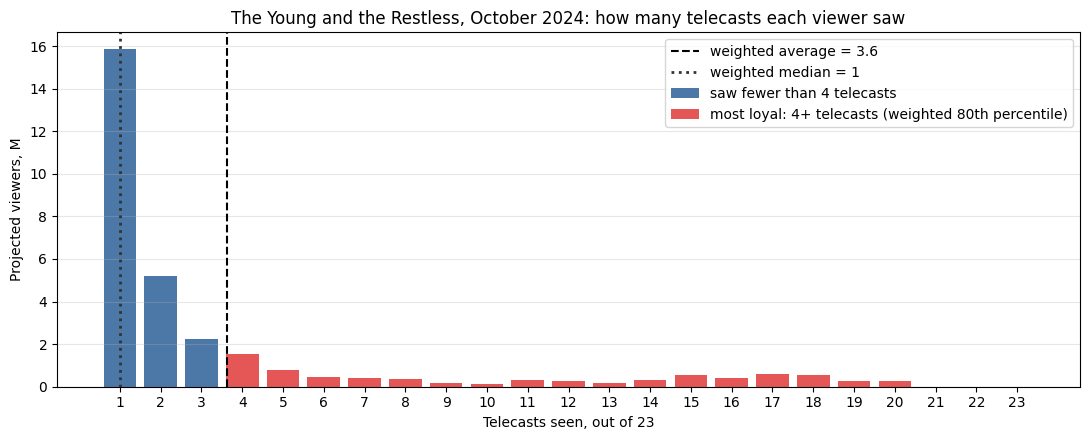

k
1     15.849
2      5.218
3      2.254
4      1.537
5      0.788
6      0.439
7      0.403
8      0.383
9      0.172
10     0.124
11     0.296
12     0.248
13     0.168
14     0.301
15     0.571
16     0.406
17     0.584
18     0.545
19     0.256
20     0.254
21     0.000
22     0.000
23     0.000


In [52]:
# 3.2 frequency distribution in projected viewers, with the most loyal viewers (3.3) highlighted
f80 = weighted_quantile(freq, fw, 0.8)
dist = (fw.groupby(freq).sum() / 1e6).reindex(range(1, len(yr) + 1), fill_value=0)

fig, ax = plt.subplots(figsize=(11, 4.5))
low = dist.index < f80
ax.bar(dist.index[low], dist[low], color="#4C78A8", label=f"saw fewer than {f80} telecasts")
ax.bar(dist.index[~low], dist[~low], color="#E45756", label=f"most loyal: {f80}+ telecasts (weighted 80th percentile)")
ax.axvline(avg_f, color="black", ls="--", label=f"weighted average = {avg_f:.1f}")
ax.axvline(med_f, color="#333333", ls=":", lw=2, label=f"weighted median = {med_f}")
ax.set_xticks(dist.index)
ax.set_xlabel(f"Telecasts seen, out of {len(yr)}")
ax.set_ylabel("Projected viewers, M")
ax.set_title(f"The Young and the Restless, {BDAYS.min():%B %Y}: how many telecasts each viewer saw")
ax.grid(alpha=0.3, axis="y")
ax.legend()
plt.tight_layout()
plt.show()
print(dist.round(3).to_string())

In [53]:
# 3.3 share of all projected views that comes from the most loyal viewers
loyal = freq >= f80
views = freq * fw
print("Weighted 80th percentile of frequency:", f80)
print(f"Most loyal viewers ({f80}+ telecasts): {fw[loyal].sum() / 1e6:.2f} M = {fw[loyal].sum() / fw.sum():.1%} "
      f"of viewers, {views[loyal].sum() / views.sum():.1%} of all projected views")
print(f"Saw only 1 telecast: {fw[freq == 1].sum() / fw.sum():.1%} of viewers | "
      f"saw fewer than the average ({avg_f:.1f}): {fw[freq < avg_f].sum() / fw.sum():.1%} of viewers | "
      f"most common frequency: {dist.idxmax()}")

Weighted 80th percentile of frequency: 4
Most loyal viewers (4+ telecasts): 7.48 M = 24.3% of viewers, 70.4% of all projected views
Saw only 1 telecast: 51.5% of viewers | saw fewer than the average (3.6): 75.7% of viewers | most common frequency: 1


**Answer:** The Young and the Restless reached **30.8 M** persons over its 23 October telecasts; the weighted average viewer saw **3.6** telecasts but the weighted median only **1**, because **51.5%** of viewers watched a single episode while a small daily core watched 15–18. The most loyal viewers, at or above the weighted 80th percentile of **4** telecasts (**24.3%** of viewers), deliver **70.4%** of all projected views, so the average lies: **75.7%** of viewers saw fewer telecasts than 3.6, a number that blends one-time samplers with a devoted core and describes almost nobody.

## Task 4 — Networks by age and gender

In [54]:
# sex (the "Sex" codes, 201/202) and age (code 300) of every person -> audience
sex_codes = attributes[attributes.attr_group == "Sex"].set_index("attr_id").attr_name
print("Sex codes:", sex_codes.to_dict())
letter = (viewer_attributes[viewer_attributes.attr_id.isin(sex_codes.index)]
          .drop_duplicates("respondent_id").set_index("respondent_id").attr_id
          .map(sex_codes).str[0].map({"M": "M", "F": "W", "W": "W"}))       # Male -> M, Female -> W
age_y = (viewer_attributes[viewer_attributes.attr_id == 300]
         .drop_duplicates("respondent_id").set_index("respondent_id").value)
band = pd.Series(np.select([age_y.between(18, 34), age_y.between(35, 54), age_y >= 55],
                           ["18–34", "35–54", "55+"], default="2–17"), index=age_y.index)
demo = (letter.reindex(band.index) + band).where(band != "2–17", "2–17")
DEMOS = ["M18–34", "W18–34", "M35–54", "W35–54", "M55+", "W55+"]
COLS = DEMOS + ["2–17"]
print("Persons by audience:", demo.value_counts().to_dict(), "| without sex or age:", int(demo.isna().sum()))

# projected minutes (minutes × weight) and raw panel minutes, by network and audience
pv = viewings.loc[viewings.resp_type.isin(PERSONS), ["respondent_id", "network_code", "start_ts", "end_ts", "weight"]]
pv = pv.assign(minutes=(abs_time(pv.end_ts) - abs_time(pv.start_ts)).dt.total_seconds() / 60,
               demo=pv.respondent_id.map(demo))
pv = pv[broadcast_day(pv.start_ts).isin(BDAYS) & (pv.minutes > 0)]           # the same sessions as in Task 1
pv["projected"] = pv.minutes * pv.weight
proj = (pv.pivot_table(index="network_code", columns="demo", values="projected", aggfunc="sum", fill_value=0)
        .reindex(columns=COLS, fill_value=0))
raw = (pv.pivot_table(index="network_code", columns="demo", values="minutes", aggfunc="sum", fill_value=0)
       .reindex(columns=COLS, fill_value=0))
print("\nProjected viewing minutes, billions:")
print((proj[DEMOS] / 1e9).round(2).to_string())

Sex codes: {201: 'Male', 202: 'Female'}
Persons by audience: {'2–17': 2206, 'W35–54': 1698, 'M35–54': 1686, 'W55+': 1337, 'M55+': 1274, 'W18–34': 1047, 'M18–34': 968} | without sex or age: 0

Projected viewing minutes, billions:
demo          M18–34  W18–34  M35–54  W35–54   M55+   W55+
network_code                                              
ABC             3.01    3.50    9.04    9.44  30.79  38.84
BRAVO           0.33    0.60    1.11    2.08   0.59   1.17
CBS             3.04    2.81    8.13    8.16  38.27  47.12
FNC             0.53    0.62    1.75    1.61  27.90  31.45
FOOD            0.38    0.54    1.71    1.95   2.45   3.72
FOX             4.39    4.57   12.80   11.16  30.88  36.91
FX              1.47    1.38    2.37    1.77   1.45   1.28
HGTV            0.40    0.54    2.28    3.05   3.58   5.28
HIST            0.26    0.23    1.41    0.89   3.72   3.20
NBC             3.91    4.53   10.99   11.64  34.27  41.39


In [55]:
# top 5 networks for each audience (billions of projected minutes)
top5 = pd.DataFrame({d: [f"{net} {v / 1e9:.1f}B" for net, v in proj[d].nlargest(5).items()] for d in DEMOS})
top5.index = pd.RangeIndex(1, len(top5) + 1, name="rank")
print(top5.to_string())

        M18–34    W18–34     M35–54     W35–54       M55+       W55+
rank                                                                
1     FOX 4.4B  FOX 4.6B  FOX 12.8B  NBC 11.6B  CBS 38.3B  CBS 47.1B
2     NBC 3.9B  NBC 4.5B  NBC 11.0B  FOX 11.2B  NBC 34.3B  NBC 41.4B
3     CBS 3.0B  ABC 3.5B   ABC 9.0B   ABC 9.4B  FOX 30.9B  ABC 38.8B
4     ABC 3.0B  CBS 2.8B   CBS 8.1B   CBS 8.2B  ABC 30.8B  FOX 36.9B
5      FX 1.5B   FX 1.4B    FX 2.4B  HGTV 3.1B  FNC 27.9B  FNC 31.5B


              weighted, %  raw panel, %  raw − weighted
network_code                                           
FX                   26.6          23.2            -3.4
BRAVO                14.8          12.7            -2.1
FOX                   8.2           7.5            -0.7
FOOD                  7.8           7.1            -0.7
NBC                   7.3           6.8            -0.5
ABC                   6.4           6.0            -0.4
HGTV                  5.8           5.2            -0.6
CBS                   5.1           5.0            -0.2
HIST                  4.8           4.4            -0.4
FNC                   1.8           1.7            -0.1
Youngest audience: FX | oldest: FNC | by raw minutes: FX / FNC


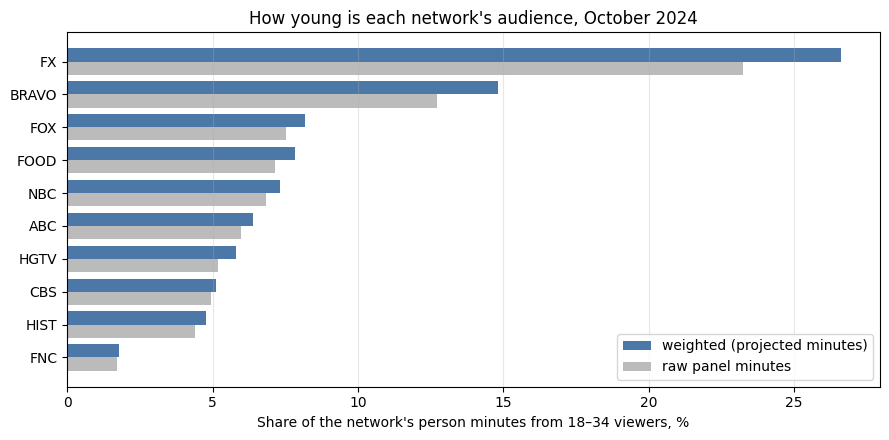

In [56]:
# youngest / oldest: share of each network's person minutes that comes from 18–34 viewers, weighted and raw
young = ["M18–34", "W18–34"]
share = pd.DataFrame({"weighted, %": proj[young].sum(axis=1) / proj.sum(axis=1) * 100,
                      "raw panel, %": raw[young].sum(axis=1) / raw.sum(axis=1) * 100}
                     ).sort_values("weighted, %", ascending=False)
share["raw − weighted"] = share["raw panel, %"] - share["weighted, %"]
print(share.round(1).to_string())
print("Youngest audience:", share["weighted, %"].idxmax(), "| oldest:", share["weighted, %"].idxmin(),
      "| by raw minutes:", share["raw panel, %"].idxmax(), "/", share["raw panel, %"].idxmin())

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(share))
ax.barh(y - 0.2, share["weighted, %"], height=0.4, color="#4C78A8", label="weighted (projected minutes)")
ax.barh(y + 0.2, share["raw panel, %"], height=0.4, color="#BBBBBB", label="raw panel minutes")
ax.set_yticks(y, share.index)
ax.invert_yaxis()
ax.set_xlabel("Share of the network's person minutes from 18–34 viewers, %")
ax.set_title(f"How young is each network's audience, {BDAYS.min():%B %Y}")
ax.grid(alpha=0.3, axis="x")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [57]:
# who is over- or under-represented: share of panel person-days vs share of the weighted population
# (index above 100 = fewer panelists than the group's share of the US, so the weights scale them up)
pdw = dw[dw.resp_type.isin(PERSONS)].assign(demo=lambda d: d.respondent_id.map(demo))
r = pdw.groupby("demo").agg(panel=("weight", "size"), population=("weight", "sum"), avg=("weight", "mean"))
rep = pd.DataFrame({"share of panel, %": r.panel / r.panel.sum() * 100,
                    "share of population, %": r.population / r.population.sum() * 100,
                    "average weight": r.avg}).reindex(COLS)
rep["index"] = rep["share of population, %"] / rep["share of panel, %"] * 100
print(rep.round(1).to_string())

        share of panel, %  share of population, %  average weight  index
demo                                                                    
M18–34                9.4                    11.5         41484.5  121.2
W18–34               10.3                    11.4         38141.8  111.4
M35–54               16.6                    12.7         26211.8   76.6
W35–54               16.7                    12.7         26054.9   76.1
M55+                 12.4                    14.7         40500.1  118.3
W55+                 13.0                    16.6         43643.9  127.5
2–17                 21.6                    20.4         32390.0   94.6


**Answer:** The four broadcast networks lead every audience (FOX for M18–34, W18–34 and M35–54, NBC for W35–54, CBS for 55+), and fifth place shows each cable niche: FX for young adults and M35–54, HGTV for W35–54, Fox News for 55+. **FX** has the youngest audience (**26.6%** of its projected minutes come from 18–34 viewers) and **Fox News** the oldest (**1.8%**, with over 90% of its minutes from viewers 55+).

Without weights the 18–34 share is lower on every network (FX **23.2%** vs 26.6%, Bravo 12.7% vs 14.8%), because the panel over-represents adults 35–54 (16.6–16.7% of panelists vs 12.7% of the population, index ≈76) and under-represents young adults (index 111–121) and people 55+ (index 118–128), which the weights correct. Raw panel numbers would therefore understate young and older audiences and overstate 35–54, making youth-skewing networks like FX and Bravo look older than they are, and they would not project to the 317 M Americans at all because they are only the minutes of about 10,000 panelists.

**Bonus:** Fox News is the oldest network, but its audience is so large that it still delivers **1.15 billion** 18–34 viewing minutes a month, more than Bravo, HGTV, Food or History, so I would sell it on an 18–34 guarantee where the advertiser pays only for the young-adult impressions actually delivered.